# E7 — Transfer Learning VGG16 + Oversampling + Data Augmentation

E7 reprend le protocole de E6 et ajoute uniquement un oversampling du jeu d'entraînement.

**Hypothèse provisoire à confirmer avec le binôme :** `RandomOverSampler(random_state=42)` équilibre la classe COVID sur la classe majoritaire (50/50).  
La validation et le test restent inchangés. Le test n'est pas utilisé pour sélectionner le modèle.


In [1]:
import pandas as pd

# Split figé commun à toutes les expériences
train_df = pd.read_csv("../covid/splits/train.csv")
val_df = pd.read_csv("../covid/splits/validation.csv")
test_df = pd.read_csv("../covid/splits/test.csv")

print("Train original :")
print(train_df["target"].value_counts())
print(train_df["target"].value_counts(normalize=True))


Train original :
target
0    11231
1     2314
Name: count, dtype: int64
target
0    0.829162
1    0.170838
Name: proportion, dtype: float64


In [2]:
from imblearn.over_sampling import RandomOverSampler

# Oversampling uniquement sur le train.
# Méthode alignée sur la dernière version disponible du notebook du binôme.
# À reconfirmer avec lui avant le lancement définitif de E7.
X_train_e7 = train_df.drop(columns=["target"])
y_train_e7 = train_df["target"]

ros_e7 = RandomOverSampler(random_state=42)
X_train_e7_os, y_train_e7_os = ros_e7.fit_resample(X_train_e7, y_train_e7)

train_e7_df = X_train_e7_os.copy()
train_e7_df["target"] = y_train_e7_os.values

# Mélange reproductible après oversampling
train_e7_df = train_e7_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Train après oversampling :")
print(train_e7_df["target"].value_counts())
print(train_e7_df["target"].value_counts(normalize=True))
print("Shape :", train_e7_df.shape)

# Contrôles : validation/test non modifiés
print("\nValidation inchangée :")
print(val_df["target"].value_counts())
print("\nTest inchangé :")
print(test_df["target"].value_counts())


Train après oversampling :
target
1    11231
0    11231
Name: count, dtype: int64
target
1    0.5
0    0.5
Name: proportion, dtype: float64
Shape : (22462, 9)

Validation inchangée :
target
0    2808
1     579
Name: count, dtype: int64

Test inchangé :
target
0    3510
1     723
Name: count, dtype: int64


In [3]:
# Copies dédiées aux générateurs Keras
train_gen_df_e7 = train_e7_df.copy()
val_gen_df_e7 = val_df.copy()
test_gen_df_e7 = test_df.copy()

train_gen_df_e7["target"] = train_gen_df_e7["target"].astype(str)
val_gen_df_e7["target"] = val_gen_df_e7["target"].astype(str)
test_gen_df_e7["target"] = test_gen_df_e7["target"].astype(str)


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input

# Même Data Augmentation que E6
train_datagen_e7 = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

# Validation : preprocessing VGG16 uniquement
val_datagen_e7 = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
COLOR_MODE = "rgb"

train_generator_e7 = train_datagen_e7.flow_from_dataframe(
    dataframe=train_gen_df_e7,
    x_col="filepath",
    y_col="target",
    target_size=IMAGE_SIZE,
    color_mode=COLOR_MODE,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_generator_e7 = val_datagen_e7.flow_from_dataframe(
    dataframe=val_gen_df_e7,
    x_col="filepath",
    y_col="target",
    target_size=IMAGE_SIZE,
    color_mode=COLOR_MODE,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Préparé pour l'évaluation finale uniquement : ne pas utiliser pour sélectionner E7.
test_generator_e7 = val_datagen_e7.flow_from_dataframe(
    dataframe=test_gen_df_e7,
    x_col="filepath",
    y_col="target",
    target_size=IMAGE_SIZE,
    color_mode=COLOR_MODE,
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 22462 validated image filenames belonging to 2 classes.
Found 3387 validated image filenames belonging to 2 classes.
Found 4233 validated image filenames belonging to 2 classes.


In [5]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

# Même architecture que E4/E6 : nouveau modèle indépendant
base_model_e7 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model_e7.trainable = False

model_e7 = Sequential([
    base_model_e7,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model_e7.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model_e7.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

early_stopping_e7 = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

checkpoint_e7 = ModelCheckpoint(
    "E7_VGG16_TL_OS_DA_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


In [7]:
history_e7 = model_e7.fit(
    train_generator_e7,
    validation_data=val_generator_e7,
    epochs=5,
    callbacks=[early_stopping_e7, checkpoint_e7],
    verbose=1
)


Epoch 1/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8315 - auc: 0.9091 - loss: 0.3873 - precision: 0.8332 - recall: 0.8289     
Epoch 1: val_loss improved from None to 0.15810, saving model to E7_VGG16_TL_OS_DA_best.keras

Epoch 1: finished saving model to E7_VGG16_TL_OS_DA_best.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 5428s 8s/step - accuracy: 0.8315 - auc: 0.9091 - loss: 0.3873 - precision: 0.8332 - recall: 0.8289 - val_accuracy: 0.9410 - val_auc: 0.9710 - val_loss: 0.1581 - val_precision: 0.8503 - val_recall: 0.7945
Epoch 2/5
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8964 - auc: 0.9624 - loss: 0.2496 - precision: 0.8961 - recall: 0.8969     
Epoch 2: val_loss improved from 0.15810 to 0.14386, saving model to E7_VGG16_TL_OS_DA_best.keras

Epoch 2: finished saving model to E7_VGG16_TL_OS_DA_best.keras
702/702 ━━━━━━━━━━━━━━━━━━━━ 4694s 7s/step - accuracy: 0.8964 - auc: 0.9624 - loss: 0.2496 - precision: 0.8961 - recall: 0.8969 - val_accuracy: 0.9457 - val_auc: 0.9787

## Résultats de validation

Les cellules suivantes produisent les mêmes éléments de contrôle que pour les autres expériences : historique, courbes, matrice de confusion et rapport de classification. Elles utilisent **uniquement la validation**.


In [8]:
import pandas as pd

history_e7_df = pd.DataFrame(history_e7.history)
history_e7_df.index = range(1, len(history_e7_df) + 1)
history_e7_df.index.name = "epoch"
display(history_e7_df)

history_e7_df.to_csv("E7_history.csv")


,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall
epoch,,,,,,,,,,
1,0.831493,0.909136,0.387281,0.833244,0.828867,0.940951,0.970951,0.158097,0.850277,0.794473
2,0.896447,0.962401,0.249566,0.896095,0.896893,0.945675,0.978743,0.143856,0.810047,0.891192
3,0.912163,0.972080,0.214500,0.911320,0.913187,0.955123,0.981198,0.125835,0.867470,0.870466
4,0.925519,0.978391,0.188480,0.924121,0.927166,0.955123,0.984371,0.119310,0.847154,0.899827
5,0.929258,0.980895,0.176298,0.927318,0.931529,0.958961,0.981422,0.115389,0.919847,0.832470


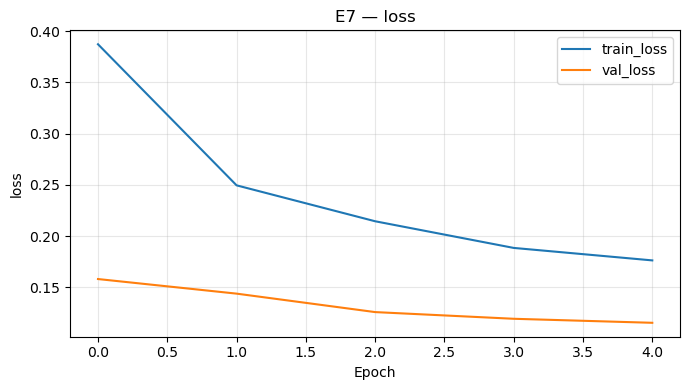

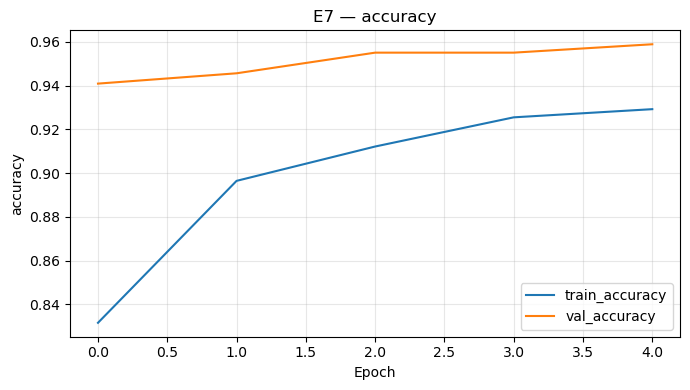

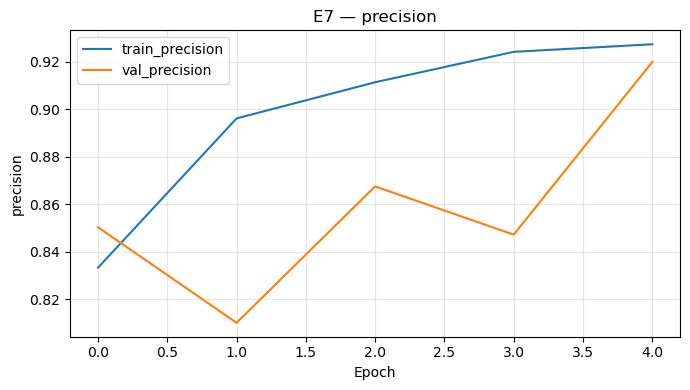

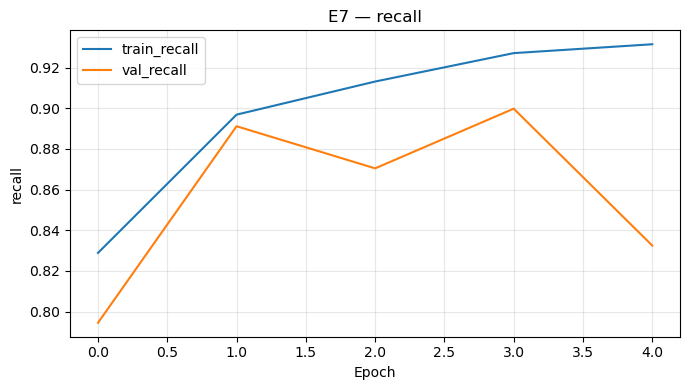

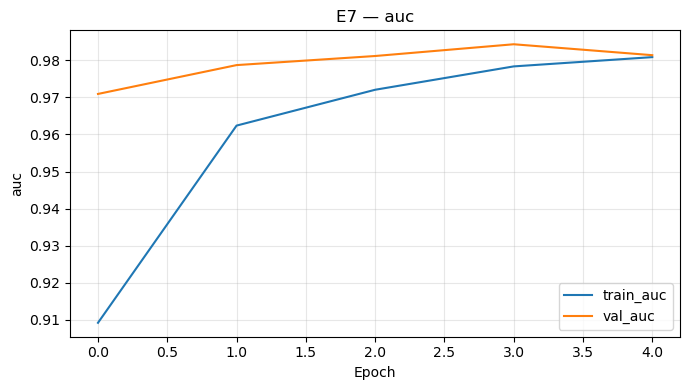

In [9]:
import matplotlib.pyplot as plt

for metric in ["loss", "accuracy", "precision", "recall", "auc"]:
    plt.figure(figsize=(7, 4))
    plt.plot(history_e7.history[metric], label=f"train_{metric}")
    plt.plot(history_e7.history[f"val_{metric}"], label=f"val_{metric}")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"E7 — {metric}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"E7_{metric}.png", dpi=150, bbox_inches="tight")
    plt.show()


106/106 ━━━━━━━━━━━━━━━━━━━━ 578s 5s/step
[[2766   42]
 [  97  482]]

              precision    recall  f1-score   support

   Non-COVID     0.9661    0.9850    0.9755      2808
       COVID     0.9198    0.8325    0.8740       579

    accuracy                         0.9590      3387
   macro avg     0.9430    0.9088    0.9247      3387
weighted avg     0.9582    0.9590    0.9581      3387



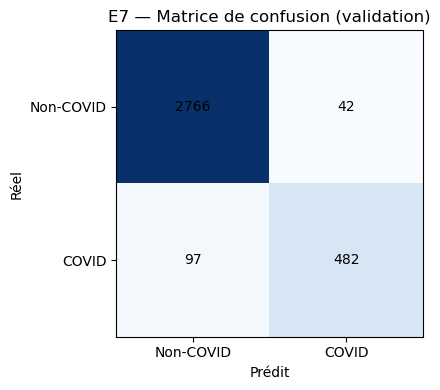

In [10]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

val_generator_e7.reset()
val_prob_e7 = model_e7.predict(val_generator_e7, verbose=1).ravel()
val_pred_e7 = (val_prob_e7 >= 0.5).astype(int)
y_true_e7 = val_generator_e7.classes

cm_e7 = confusion_matrix(y_true_e7, val_pred_e7)
print(cm_e7)
print()
print(classification_report(
    y_true_e7,
    val_pred_e7,
    target_names=["Non-COVID", "COVID"],
    digits=4
))

report_e7 = classification_report(
    y_true_e7,
    val_pred_e7,
    target_names=["Non-COVID", "COVID"],
    output_dict=True
)
pd.DataFrame(report_e7).transpose().to_csv("E7_classification_report.csv")

plt.figure(figsize=(5, 4))
plt.imshow(cm_e7, cmap="Blues")
plt.title("E7 — Matrice de confusion (validation)")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.xticks([0, 1], ["Non-COVID", "COVID"])
plt.yticks([0, 1], ["Non-COVID", "COVID"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_e7[i, j], ha="center", va="center")

plt.tight_layout()
plt.savefig("E7_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
